# Toric code — solution

**Goals**

- Create $\mathbb Z_2$-symmetric tensors with YASTN.
- Build a toric-code PEPS from a local parity constraint.
- Verify its stabilizers and extract the topological correction to its Rényi entropy.

**Before you start**

- Select a Python kernel with YASTN installed; see the [installation instructions](../README.md#installation).

- Run cells from top to bottom. This notebook completes the
  [exercise notebook](Toric_code_exercise.ipynb) and includes optional appendices.


In [1]:
# Provided: imports and symmetry configuration.
from itertools import product

import numpy as np
import matplotlib.pyplot as plt
import yastn

# Use the NumPy backend and Z2 symmetry throughout.
z2_config = yastn.make_config(backend="np", sym="Z2", default_dtype="float64")


## 1. Create $\mathbb Z_2$-symmetric tensors

- A tensor leg is an index. YASTN groups the states on each leg into **charge sectors**
  and stores only blocks that obey charge conservation.
  Start with a rank-two tensor (a matrix) $M$. Each YASTN `Leg` specifies:

    - `s`: the signature, $+1$ (ingoing) or $-1$ (outgoing).
    - `t`: the charge labels, here `(0, 1)` for even and odd parity.
    - `D`: the dimension of each sector, here `(2, 1)`.

- **Arrow convention:** arrows point into a tensor for signature $+1$ and away
  from it for $-1$. Contracted legs have opposite signatures.
  Numbers in parentheses, such as `(0)`, label zero-based leg positions.

- For example, the matrix below has leg order `(q1, q2)` and signatures `(+,-)`:

  ```text
  q1(0) ---> [M] ---> q2(1)
  ```

- Each leg has dimension $2+1=3$. `leg.conj()` reverses its signature.
  The tensor's total charge is `n`. Here charge conservation means

  $$
  (q_1-q_2)\bmod2=n.
  $$

- For `n=0`, only equal-charge blocks are allowed:

  $$
  M=\begin{pmatrix}M_{00}&0\\0&M_{11}\end{pmatrix},
  $$

  where $M_{00}$ is a $2\times2$ block and $M_{11}$ is a $1\times1$ block.
  The off-diagonal blocks are symmetry-forbidden and are not stored.

- For $\mathbb Z_2$, charges add modulo two: $1+1=0$ and $-q=q$.
  The arrows still specify which legs can be contracted.
  Run the worked example below: `yastn.zeros` allocates allowed blocks and
  `set_block` fills them.


In [2]:
# Provided: worked example of symmetric blocks.
# Two even states and one odd state on each leg.
leg = yastn.Leg(z2_config, s=1, t=(0, 1), D=(2, 1))
M = yastn.zeros(config=z2_config, legs=(leg, leg.conj()), n=0)

M.set_block(ts=(0, 0), val=np.array([[1., 2.], [3., 4.]]))
M.set_block(ts=(1, 1), val=np.array([[5.]]))

print("Dense shape:", M.get_shape())
print("Stored blocks (q1, q2):", M.get_blocks_charge())
print("Dense representation (missing blocks become zeros):")
print(M.to_numpy())


Dense shape: (3, 3)
Stored blocks (q1, q2): ((0, 0), (1, 1))
Dense representation (missing blocks become zeros):
[[1. 2. 0.]
 [3. 4. 0.]
 [0. 0. 5.]]


### 1.1. Two tensor operations used below

- `yastn.einsum` follows the usual index notation. For example,

  ```python
  C = yastn.einsum("ij,jk->ik", M, M)
  ```

  Here `j` is summed, and the labels after `->` set the output leg order.
  Contracted legs must have opposite signatures; `M.conj()` conjugates the entries
  and reverses all signatures.

- **Fusion** combines several indices into one. For a five-leg tensor `T`,
  `T.fuse_legs(axes=(0,(1,2),(3,4)), mode="hard")` returns three legs:
  `[0, (1,2), (3,4)]`. We use this to group ket and bra spin indices in section 5.
  The fusion calls are provided.


## 2. Toric-code ground state

- The toric code places one qubit on each edge of a square lattice.
  With Pauli matrices $X$ and $Z$, its Hamiltonian is

  $$
  H=-\sum_v A_v-\sum_p B_p,\qquad
  A_v=\prod_{e\ni v}Z_e,\qquad
  B_p=\prod_{e\in\partial p}X_e.
  $$

- Here $v$ is a vertex, $p$ a plaquette, and each product acts on four edges.
  These operators commute. Ground states satisfy $A_v=B_p=+1$ everywhere.

### 2.1. The closed-loop wavefunction

- Work in the $Z$ basis: $Z_e|s_e\rangle=(-1)^{s_e}|s_e\rangle$.
  Draw an occupied edge when $s_e=1$.

- $A_v=+1$ requires an even number of occupied edges at each vertex, so no loop can end there.

- $B_p$ flips the four bits around a plaquette, preserving this even-parity condition.

- On a finite lattice, the equal-amplitude loop state is

  $$
  |\psi_{\mathrm{loop}}\rangle
  =\frac{1}{\sqrt{\mathcal N}}\sum_{C\in\mathcal C}|C\rangle,
  $$

  where $\mathcal C$ contains all even-parity configurations and $\mathcal N=|\mathcal C|$.
  Plaquette flips permute these configurations, so this state has $A_v=B_p=+1$.
  We will represent it with local tensors and repeat them on the infinite lattice.

<!--
### Optional: Four ground states on a torus

Periodic boundary conditions identify opposite sides of the lattice.
A contractible loop can shrink by local plaquette flips. A noncontractible loop
winds around the torus and cannot shrink to a point.

<p align="center">
  <img src="figures/toric_code_loops.png" alt="Contractible and noncontractible loops on a periodic lattice" width="850">
</p>

Choose two noncontractible **dual measuring loops**, $\gamma_a^*$ and $\gamma_b^*$,
shown as dashed lines below. For each occupied-edge configuration $C$, define

$$
a=N(C\cap\gamma_a^*)\bmod2,\qquad
b=N(C\cap\gamma_b^*)\bmod2.
$$

Here $N$ counts crossings between $C$ and the measuring loop.
A local plaquette flip changes each crossing count by
zero or two, so it preserves $(a,b)$. The configurations therefore are classified into
four winding-parity sectors $\mathcal C_{ab}$.

<p align="center">
  <img src="figures/toric_code_sectors.png" alt="Example closed-loop configurations in the four winding-parity sectors" width="850">
</p>

Each panel shows **one configuration**.
The **quantum ground state** in each sector sums equally over all its configurations:

$$
|\psi_{ab}\rangle
=\frac{1}{\sqrt{|\mathcal C_{ab}|}}\sum_{C\in\mathcal C_{ab}}|C\rangle,
\qquad a,b\in\{0,1\}.
$$

These four states are orthogonal and satisfy the same local conditions
$A_v=B_p=+1$. They span the four-dimensional ground-state space on a torus.

The state $|\psi_{\mathrm{loop}}\rangle$ defined above is an equal
superposition of these four states:

$$
|\psi_{\mathrm{loop}}\rangle=\frac12\sum_{a,b=0}^1|\psi_{ab}\rangle.
$$
We construct $|\psi_{\mathrm{loop}}\rangle$ below. The appendix resolves the
four sectors appropriate to the entanglement cut.
-->


### 2.2. Encode the four-edge constraint with $\mathbb Z_2$ symmetry

- The even-parity constraint at each vertex can be encoded in a four-leg tensor $Q$.
  We can write $Q$ as a **$\mathbb Z_2$-symmetric tensor** by identifying each edge bit
  $s_e$ with a charge $q_e=s_e$, with one state in each sector $q_e=0,1$.

- Choose signatures `(+,+,-,-)` in `(u,l,d,r)` order and total charge `n=0`.
  Charge conservation then requires

  $$
  (q_u+q_l-q_d-q_r)\bmod2=0.
  $$

- Since $-q=q$ modulo two, this condition says that the four edge bits have even parity.
  Set every allowed block to one to obtain

  $$
  Q_{s_u s_l s_d s_r}=
  \begin{cases}
  1,&s_u+s_l+s_d+s_r=0\pmod2,\\
  0,&\text{otherwise}.
  \end{cases}
  $$

  ```text
                                            s_u(0)
                                              |
                                              v
                                  s_l(1) ---> [Q] ---> s_r(3)
                                              |
                                              v
                                            s_d(2)
  ```

- Place $Q$ at every original vertex. The amplitude of a fixed spin configuration is

  $$
  \Psi(\{s_e\})\propto\prod_v Q_{s_u(v)s_l(v)s_d(v)s_r(v)}.
  $$

  This gives equal weight to every closed-loop configuration and zero to the others.
  Use `yastn.ones` to fill the eight symmetry-allowed blocks with one.


In [3]:
def constraint_tensor(config):
    """Four-edge even-parity constraint at an original lattice vertex."""
    leg = yastn.Leg(config, s=1, t=(0, 1), D=(1, 1))
    return yastn.ones(config=config, legs=(leg, leg, leg.conj(), leg.conj()), n=0)


Q_z2 = constraint_tensor(z2_config)
print(f"Z2: {len(Q_z2.get_blocks_charge())} stored scalars / 16 dense entries")
print("Allowed (s_u, s_l, s_d, s_r):", Q_z2.get_blocks_charge())
assert len(Q_z2.get_blocks_charge()) == 8
assert Q_z2.s == (1, 1, -1, -1)


Z2: 8 stored scalars / 16 dense entries
Allowed (s_u, s_l, s_d, s_r): ((0, 0, 0, 0), (0, 0, 1, 1), (0, 1, 0, 1), (0, 1, 1, 0), (1, 0, 0, 1), (1, 0, 1, 0), (1, 1, 0, 0), (1, 1, 1, 1))


### 2.3. Visualize the allowed vertices

- The provided helper reads the charge labels from `Q_z2` to draw its eight allowed vertices.

- A thick segment denotes an occupied edge; a faint segment denotes an empty edge.

- Check that every vertex has even occupancy. Arrows indicate leg signatures.


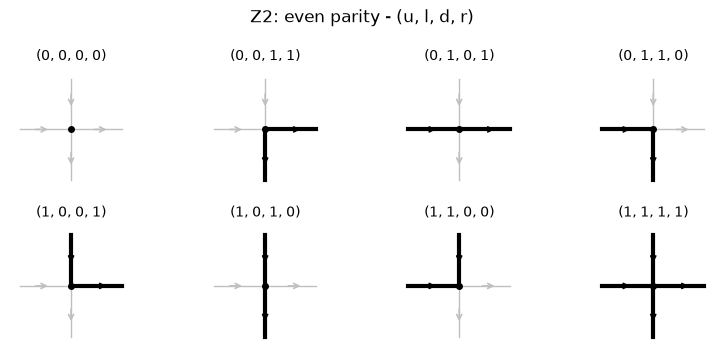

In [4]:
# Provided: vertex visualization.
def plot_vertices(Q):
    """Draw allowed charges; arrows point into + legs and away from - legs."""
    vertices = list(Q.get_blocks_charge())
    fig, axes = plt.subplots(2, 4, figsize=(8, 3.6))
    endpoints = [(0, 1), (-1, 0), (0, -1), (1, 0)]  # up, left, down, right
    for ax, charges in zip(axes.flat, vertices):
        for q, signature, (x, y) in zip(charges, Q.s, endpoints):
            color = "black" if q else "0.75"
            ax.plot([0, x], [0, y], color=color, linewidth=3 if q else 1)
            start, end = (0.75, 0.4) if signature == 1 else (0.4, 0.75)
            ax.annotate("", xy=(end*x, end*y), xytext=(start*x, start*y),
                        arrowprops={"arrowstyle": "->", "color": color,
                                    "lw": 1.2, "mutation_scale": 9})
        ax.plot(0, 0, "ko", markersize=4)
        ax.set_title(str(charges), fontsize=10)
        ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
        ax.axis("off")
    for ax in axes.flat[len(vertices):]:
        ax.axis("off")
    fig.suptitle("Z2: even parity - (u, l, d, r)")
    fig.tight_layout()
    return fig


plot_vertices(Q_z2)
plt.show()


### 2.4. Expose the physical spins with $P$

- Summing every edge index of the $Q$ network counts closed-loop configurations.
  A wavefunction must retain one open index for each physical spin.
  Insert a **copy tensor** on every edge:

  $$
  P^s_{q,q'}=\delta_{q,q'}\delta_{s,q}.
  $$

- It copies the shared virtual bit onto the physical spin: $s=q=q'$.
  The network now has $Q$ at every vertex and $P$ on every edge:

  <p align="center">
    <img src="figures/toric_code_edge_arrows.png" alt="Original square lattice with Q at vertices, P on edges, and an orange physical spin leg on each P" width="850">
  </p>

- In code, `P[s,q,q_next]` has signatures `(+,+,-)`.
  Its two virtual legs carry the same charge $q=0,1$.
  The physical leg is a single charge-zero sector of dimension two, with basis $|0\rangle,|1\rangle$.

- The copy tensor is provided; run the next cell.


In [5]:
# Provided: physical copy tensor.
def physical_copy(config):
    """P[s, q, q_next] exposes the shared virtual bit as a physical spin."""
    P = yastn.Tensor(config=config, s=(1, 1, -1), n=0)
    for q in (0, 1):
        values = np.zeros((2, 1, 1))
        values[q, 0, 0] = 1
        P.set_block(ts=(0, q, q), Ds=(2, 1, 1), val=values)
    return P


P_z2 = physical_copy(z2_config)
print("Copy tensor shape (s, q, q_next):", P_z2.get_shape())


Copy tensor shape (s, q, q_next): (2, 2, 2)


## 3. From the edge-spin network to a square-lattice PEPS

- A standard PEPS associates a tensor with each site.
  Its virtual legs connect neighboring sites; its open physical leg labels the local spin.
  In the following, we convert the edge-spin network to the standard PEPS geometry.

- Split each $Q$ into four three-leg factors, two $R_1$ and two $R_2$.
  Both $R_1$ and $R_2$ enforce even parity:

  $$
  (R_1)_{q_0q_1q_2}=(R_2)_{q_0q_1q_2}
  =\delta_{(q_0+q_1+q_2)\bmod2,\,0}.
  $$

- Their entries are identical, but their signatures differ:
  `R1` has `(+,+,-)` and `R2` has `(-,-,+)` in `(q0,q1,q2)` order.

  ```text
                                (0)                            (0)
                                |                              ^
                                v                              |
                      (1) ---> [R1] ---> (2)          (1) <--- [R2] <--- (2)
  ```

- Place $R_1$ at the upper/right parts of each original vertex and $R_2$ at the lower/left parts.
  Every bond joins opposite signatures; the code below supplies the factor axes.

  $$
  Q_{uldr}=\frac12\sum_{i,j,k,m}
  (R_1)_{uij}(R_1)_{jkr}(R_2)_{dkm}(R_2)_{mil}.
  $$

  <p align="center">
    <img src="figures/toric_code_embedded_R1_R2.png" alt="R1 and R2 factors embedded in the original lattice with directed bonds; outlined P-R1-R2 groups become the A and B sites of a square-lattice PEPS" width="850">
  </p>

- We then group one $P$ with two neighboring $R$ factors, as illustrated in the figure.
  The blue groups become $A$ and the green groups become $B$.


In [6]:
def splitter_tensors(config):
    """R1 has signatures (+,+,-); R2 has (-,-,+). Both have total charge zero."""
    leg = yastn.Leg(config, s=1, t=(0, 1), D=(1, 1))
    R1 = yastn.ones(config=config, legs=(leg, leg, leg.conj()), n=0)
    R2 = yastn.ones(config=config, legs=(leg.conj(), leg.conj(), leg), n=0)
    return R1, R2


R1, R2 = splitter_tensors(z2_config)
# Clockwise from the top: R1[u,i,j], R1[j,k,r], R2[d,k,m], R2[m,i,l].
# Internal labels i,j,k,m are summed; output legs are (u,l,d,r).
Q_from_R = yastn.einsum("Uij,jkR,Dkm,miL->ULDR", R1, R1, R2, R2) / 2
assert Q_from_R.s == Q_z2.s
np.testing.assert_array_equal(Q_from_R.to_numpy(), Q_z2.to_numpy())
print("Verified: the R1/R2 contraction equals Q.")


Verified: the R1/R2 contraction equals Q.


### 3.1. Build the site tensors

- Contract the three tensors within each outlined group:

  $$
  \begin{aligned}
  A^s_{uldr}&=\sum_{x,y}(R_1)_{ulx}\,P^s_{xy}\,(R_2)_{dry},\\
  B^s_{uldr}&=\sum_{x,y}(R_2)_{xru}\,P^s_{xy}\,(R_1)_{yld}.
  \end{aligned}
  $$

- In code, the physical leg is **last**: `(u,l,d,r,s)`, with signatures `(+,+,-,-,+)`.
  The virtual bond dimension is $D=2$ and the physical spin dimension is $d=2$.
  The omitted factors of $1/2$ only change the state's overall normalization.

- Rotate the drawing clockwise by $45^\circ$ to obtain the PEPS lattice.
  Each new site represents one original edge spin: $A$ comes from horizontal edges and $B$ from vertical edges.
  Use the repeating unit cell

  ```text
                                                A B
                                                B A
  ```

- YASTN coordinates are `(row,column)`, with rows increasing downward.
  Use $A$ for even `row+column` and $B$ for odd `row+column`.
  Virtual arrows point right and down; the physical arrow points into each site.


In [7]:
def make_site_tensor(P, R1, R2, orientation):
    """Contract P, R1, R2 into legs (u,l,d,r,s), with signatures (+,+,-,-,+)."""
    if orientation == "A":
        return yastn.einsum("ulx,sxy,dry->uldrs", R1, P, R2)
    return yastn.einsum("xru,sxy,yld->uldrs", R2, P, R1)


A_z2 = make_site_tensor(P_z2, R1, R2, "A")
B_z2 = make_site_tensor(P_z2, R1, R2, "B")
assert A_z2.s == B_z2.s == (1, 1, -1, -1, 1)
unit_cell = {
    (0, 0): A_z2, (0, 1): B_z2,
    (1, 0): B_z2, (1, 1): A_z2,
}
for site, tensor in unit_cell.items():
    print(f"{site}: shape {tensor.get_shape()}")


(0, 0): shape (2, 2, 2, 2, 2)
(0, 1): shape (2, 2, 2, 2, 2)
(1, 0): shape (2, 2, 2, 2, 2)
(1, 1): shape (2, 2, 2, 2, 2)


## 4. Converge the environment with YASTN

- To measure an observable, contract the infinite network $\langle\psi|O|\psi\rangle$
  and divide by $\langle\psi|\psi\rangle$.
  The bra and ket form a **double layer**; physical indices outside $O$ are summed.

- We use CTMRG to approximate the surrounding network with four corner tensors
  and four sets of edge tensors. Their bond dimension $\chi$ controls the approximation.

- The full CTMRG setup using YASTN is provided. Run the next cell and check that `Converged: True`.
  Reference: [YASTN CTM environment](https://yastn.github.io/yastn/fpeps/environment_ctm.html).


In [8]:
# Provided: the complete CTMRG setup and convergence.
import yastn.tn.fpeps as fpeps

geometry = fpeps.SquareLattice(dims=(2, 2), boundary="infinite")
psi_infinite = fpeps.Peps(geometry, tensors=unit_cell)
env_ctm = fpeps.EnvCTM(psi_infinite, init="eye")

chi = 8
ctm_info = env_ctm.ctmrg_(
    opts_svd={"D_total": chi, "tol": 1e-12},
    max_sweeps=40,
    corner_tol=1e-10,
)
print(f"Converged: {ctm_info.converged}; sweeps: {ctm_info.sweeps}; "
      f"corner residual: {ctm_info.max_dsv:.2e}; boundary dimension: {ctm_info.max_D}")
assert ctm_info.converged


Converged: True; sweeps: 2; corner residual: 0.00e+00; boundary dimension: 2


### 4.1. Measure stabilizers and magnetization

- After regrouping, each original star or plaquette operator acts on the four
  corners of a plaquette of the new PEPS lattice:

  ```text
       A(0,0) ---> B(0,1) ---> A(0,2)
          |          |          |
          v  ZZZZ    v  XXXX    v
          |          |          |
       B(1,0) ---> A(1,1) ---> B(1,2)
  ```

  The left plaquette measures $A_v$; the right measures $B_p$.

- Check the following for our constructed PEPS:

    - $\langle A_v\rangle=\langle B_p\rangle=1$.
    - Single-spin magnetizations $\langle X\rangle=\langle Z\rangle=0$ on both site types.

- The vanishing magnetizations show no single-spin magnetic order.
  Section 5 examines the state's entanglement.


In [9]:
# Provided: operators, CTM measurements, and checks.
def spin_operator(matrix):
    """A one-qubit operator on the neutral physical leg."""
    operator = yastn.Tensor(config=z2_config, s=(1, -1), n=0)
    operator.set_block(ts=(0, 0), Ds=(2, 2), val=matrix)
    return operator


X = spin_operator(np.array([[0., 1.], [1., 0.]]))
Z = spin_operator(np.diag([1., -1.]))
av = env_ctm.measure_2x2(Z, Z, Z, Z, sites=((0, 0), (0, 1), (1, 0), (1, 1)))
bp = env_ctm.measure_2x2(X, X, X, X, sites=((0, 1), (0, 2), (1, 1), (1, 2)))
print(f"<A_v> = {av:.12f}; <B_p> = {bp:.12f}")
np.testing.assert_allclose([av, bp], [1, 1], atol=1e-10)

magnetizations = {}
for site in geometry.sites():
    for label, operator in [("X", X), ("Z", Z)]:
        value = env_ctm.measure_1site(operator, site=site)
        magnetizations[site, label] = value
        print(f"<{label}> at {tuple(site)} = {value:.3e}")
np.testing.assert_allclose(list(magnetizations.values()), 0, atol=1e-10)


<A_v> = 1.000000000000; <B_p> = 1.000000000000
<X> at (0, 0) = 0.000e+00
<Z> at (0, 0) = 0.000e+00
<X> at (1, 0) = 0.000e+00
<Z> at (1, 0) = 0.000e+00
<X> at (0, 1) = 0.000e+00
<Z> at (0, 1) = 0.000e+00
<X> at (1, 1) = 0.000e+00
<Z> at (1, 1) = 0.000e+00


## 5. Rényi entropy from a contractible patch

- Choose a region $R$ and trace out all spins outside it:
  $\rho_R=\operatorname{Tr}_{\bar R}|\psi\rangle\langle\psi|$ for a normalized state.
  This **reduced density matrix (RDM)** describes measurements within $R$.
  Its purity determines the second Rényi entropy:

  $$
  S_2(R)=-\log\operatorname{Tr}(\rho_R^2).
  $$

- For a large disk with one boundary, the entropy obeys the area law with a topological correction:

  $$
  S_2(R)=\alpha_2 L-\gamma+\cdots,\qquad \gamma=\log\mathcal D,
  $$

  where $L$ measures the boundary size and $\mathcal D$ is the **total anyon quantum dimension**.
  The toric code has four anyon types, each of quantum dimension one.
  Thus $\mathcal D=\sqrt{1+1+1+1}=2$ and we expect $\gamma=\log2$.


### 5.1. Construct the patch RDM $\rho_R$

- Take a rectangular patch with two rows and $w$ columns.
  The converged `env_ctm` approximates the contraction outside it, tracing out the surrounding spins.

- At each site of the patch, form the double layer $E_A=A\otimes A^*$ (or $E_B=B\otimes B^*$).
  Keep the physical ket and bra legs open, and fuse each virtual ket/bra pair.
  Conjugation reverses the bra arrows; a fused virtual leg follows the ket direction.
  For $w=2$, the unnormalized RDM $\widetilde\rho_R$ has the network

  ```text
         tl ---> t0 ---> t1 ---> tr
          ^       |       |       |
          |       v       v       v
         l0 ---> EA ---> EB ---> r0
          ^       |       |       |
          |       v       v       v
         l1 ---> EB ---> EA ---> r1
          ^       |       |       |
          |       v       v       v
         bl <--- b0 <--- b1 <--- br
  ```

  Here `EA` and `EB` are the double layers of $A$ and $B$; their physical legs are omitted.
  `t,b,l,r` denote top, bottom, left, and right CTM edges; `tl,tr,bl,br` are corners.

Contract this network in four steps:

1. **Build the side boundaries.** Contract `tl-l0-l1-bl` into `left` and
   `tr-r0-r1-br` into `right`. Their four remaining legs connect to the top CTM
   edge, upper site, lower site, and bottom CTM edge. Combine these four legs
   into one boundary index.

2. **Build each column from top to bottom.** Contract `t0` with the upper site,
   then the lower site, then `b0`; repeat for the other columns.
   Combine the four left virtual legs into `i` and the four right legs into `j`.
   The result is `column[i, j, p, q, P, Q]`: `p,q` are the top/bottom ket spins,
   and `P,Q` are their bra partners. These capital letters label physical indices,
   not the tensors $P$ and $Q$ from the construction.

   <p align="center">
     <img src="figures/ctm_strip_column.png" alt="Contract the top CTM edge, upper double layer, lower double layer, and bottom CTM edge; fuse the side bonds into a column with ket legs p and q above and bra legs P and Q below" width="850">
   </p>

   Fuse `i=(a,b,l,m)` and `j=(c,e,r,s)`. 

3. **Grow the patch from left to right.** Start with `left` and attach `column[0]`.
   Attach the remaining columns one at a time through the shared virtual index:

   ```text
                p q             p q
                | |             | |
   left --> [column[0]] --> [column[1]] --> right
                | |             | |
                P Q             P Q
   ```

   Keep every physical leg open. After each addition, group all accumulated ket
   indices into one index and all bra indices into another.

4. **Close and normalize.** Contract the remaining virtual index with `right`.
   Only the physical ket and bra indices remain, giving a matrix
   $\widetilde\rho_R$. Normalize it as
   $\rho_R=\widetilde\rho_R/\operatorname{Tr}\widetilde\rho_R$.

- The spin order is **column by column**, upper spin then lower spin.
  For $w=2$, the four-spin RDM is a $16\times16$ matrix.
  Its dimension grows as $2^{2w}\times2^{2w}$.

The first code cell below provides `strip_transfer`; read the function to understand
what it computes and run it unchanged.


In [10]:
assert ctm_info.converged

# Provided: CTM boundaries, double layers, and column bookkeeping.
def strip_transfer(psi, env, width):
    """CTM boundaries and double-layer columns for a 2-by-width site patch."""
    # Side boundaries: arrows indicate signatures; (i) is the leg position.
    #
    # [tl]--a(1)-->             (0)a-->[tr]
    #   ^ x(0)                          | x(1)
    #   |                               |
    #   | x(2)                          v x(0)
    #  [l]--l(1)-->             (1)r-->[r]
    #   ^ y(0)                          | y(2)
    #   |                               |
    #   | y(2)                          v y(0)
    #  [l]--m(1)-->             (1)s-->[r]
    #   ^ z(0)                          | z(2)
    #   |                               |
    #   | z(1)                          v z(0)
    # [bl]<--b(0)--             (1)b<--[br]
    #
    # left[a(0), b(1), l(2), m(3)]; right[a(0), b(1), r(2), s(3)].
    top, bottom = env[(0, 0)], env[(1, 0)]
    left = yastn.einsum("xa,ylx,zmy,bz->ablm", top.tl, top.l, bottom.l, bottom.bl)
    top, bottom = env[(0, width - 1)], env[(1, width - 1)]
    right = yastn.einsum("ax,xry,ysz,zb->abrs", top.tr, top.r, bottom.r, bottom.br)
    columns = []
    for x in range(width):
        layers = []
        for y in (0, 1):
            A = psi[(y, x)]
            # E = A[p] x conj(A)[q]; keep both physical indices open.
            E = yastn.einsum("uldrp,ULDRq->uUlLdDrRpq", A, A.conj())
            layers.append(E.fuse_legs(axes=((0, 1), (2, 3), (4, 5), (6, 7), 8, 9), mode="hard"))
        # One column: [E] is a double layer after virtual ket/bra fusion.
        #
        # (0)a --> [t] --> c(2)
        #           | u(1)
        #           |
        #           v u(0)
        # (1)l --> [E] --> r(3)
        #           | v(2)
        #           |
        #           v v(0)
        # (1)m --> [E] --> s(3)
        #           | d(2)
        #           |
        #           v d(1)
        # (2)b <-- [b] <-- e(0)
        #
        #
        # Contract u, then v, then d. All physical legs stay open.
        column = yastn.einsum("auc,edb,ulvrpP,vmdsqQ->ablmcerspqPQ",
                              env[(0, x)].t, env[(1, x)].b, *layers, order="uvd")
        # Fuse (a,b,l,m) -> i and (c,e,r,s) -> j.
        # Result: column[i(0), j(1), p(2), q(3), P(4), Q(5)].
        columns.append(column.fuse_legs(axes=((0, 1, 2, 3), (4, 5, 6, 7), 8, 9, 10, 11), mode="hard"))
    # Fused directions: [left] --> i(0); j(0) --> [right].
    left = left.fuse_legs(axes=((0, 1, 2, 3),), mode="hard")
    right = right.fuse_legs(axes=((0, 1, 2, 3),), mode="hard")
    return left, columns, right


In [11]:
def ctm_strip_rdm(psi, env, width):
    """Normalized RDM; spin order is top/bottom in each successive column."""
    left, columns, right = strip_transfer(psi, env, width)
    # 1. Attach the first column; a joins left(0) to column(0).
    #
    #                  p(2), q(3)
    #                      |
    #                      |
    # [left] ----a----> [column] ----b(1)---->
    #                      |
    #                      |
    #                  P(4), Q(5)
    #
    rho = yastn.einsum("a,abpqPQ->bpqPQ", left, columns[0])
    # Fuse physical legs: rho[b(0), (p,q)(1), (P,Q)(2)].
    rho = rho.fuse_legs(axes=(0, (1, 2), (3, 4)), mode="hard")
    for column in columns[1:]:
        # 2. Append a column; a joins rho(0) to column(0).
        #
        #   i(1)              p(2), q(3)
        #     |                   |
        #     |                   |
        #   [rho] ----a----> [column] ----b(1)---->
        #     |                   |
        #     |                   |
        #   j(2)              P(4), Q(5)
        #
        # Keep ket legs together, then bra legs: (b,i,p,q,j,P,Q).
        rho = yastn.einsum("aij,abpqPQ->bipqjPQ", rho, column)
        # Fuse to rho[b(0), (i,p,q)(1), (j,P,Q)(2)].
        rho = rho.fuse_legs(axes=(0, (1, 2, 3), (4, 5, 6)), mode="hard")
    # 3. Close the boundary; a joins rho(0) to right(0).
    #
    #   i(1)
    #     |
    #     |
    #   [rho] ----a----> [right]
    #     |
    #     |
    #   j(2)
    #
    # Result: rho[i(0), j(1)]. Divide by its trace.
    rho = yastn.einsum("aij,a->ij", rho, right)
    return rho / yastn.einsum("ii->", rho).to_number()


rho_2x2 = ctm_strip_rdm(psi_infinite, env_ctm, 2)
print("2x2 patch RDM shape:", rho_2x2.get_shape())

rho_dense = rho_2x2.to_numpy()
np.testing.assert_allclose(rho_dense, rho_dense.conj().T, atol=1e-12)
np.testing.assert_allclose(np.trace(rho_dense), 1, atol=1e-12)
print("RDM checks passed: Hermitian and trace one.")


2x2 patch RDM shape: (16, 16)
RDM checks passed: Hermitian and trace one.


In [12]:
def ctm_strip_purity(psi, env, width):
    """Contract two replicas to obtain Tr(rho**2) without storing the RDM."""
    left, columns, right = strip_transfer(psi, env, width)
    norm_boundary = left

    # Start with two left boundaries; fuse their open legs (a,c) into leg (0).
    purity_boundary = yastn.einsum("a,b->ab", left, left)
    purity_boundary = purity_boundary.fuse_legs(axes=((0, 1),), mode="hard")

    for column in columns:
        # One-copy norm: trace the physical legs (P=p, Q=q).
        # [norm_boundary] --a(0)--> (0)a--[tr_phys(column)]--b(1)-->
        norm_boundary = yastn.einsum("a,abpqpq->b", norm_boundary, column)
        # Two copies: each bra connects to the other copy's ket.
        #
        #             +----------- p,q -----------+
        #             |                           |
        # (0)a --> [copy 1] --> b(1)               |
        #             |                           |
        #            P,Q                          |
        #             |                           |
        # (0)c --> [copy 2] --> d(1)               |
        #             |                           |
        #             +---------------------------+
        #
        # P,Q: copy 1 legs (4,5) -> copy 2 legs (2,3); p,q go the other way.
        # Result: purity_transfer[a(0), c(1), b(2), d(3)].
        purity_transfer = yastn.einsum("abpqPQ,cdPQpq->acbd", column, column)
        # Fuse (a,c) and (b,d) into purity_transfer[left(0), right(1)].
        purity_transfer = purity_transfer.fuse_legs(axes=((0, 1), (2, 3)), mode="hard")
        # [purity_boundary] --(a,c)--> [purity_transfer] --(b,d)-->
        # Contract purity_boundary(0) with purity_transfer(0); the new boundary is purity_transfer(1).
        purity_boundary = yastn.einsum("a,ab->b", purity_boundary, purity_transfer)

    # Close the one-copy and two-copy boundaries.
    # [norm_boundary]   ----a----> [right]
    # [purity_boundary] --(a,c)--> [right x right]
    right_pair = yastn.einsum("a,b->ab", right, right)
    right_pair = right_pair.fuse_legs(axes=((0, 1),), mode="hard")
    norm = yastn.einsum("a,a->", norm_boundary, right).to_number()
    purity_numerator = yastn.einsum("a,a->", purity_boundary, right_pair).to_number()

    # Normalize by the squared one-copy norm.
    purity = purity_numerator / norm**2
    return purity


# Check the two-copy contraction against the explicit four-spin RDM.
purity_from_rdm = yastn.einsum("ij,ji->", rho_2x2, rho_2x2).to_number()
purity_from_transfer = ctm_strip_purity(psi_infinite, env_ctm, 2)
np.testing.assert_allclose(purity_from_transfer, purity_from_rdm, atol=1e-12)
print(f"2x2 purity: RDM = {purity_from_rdm:.8f}; transfer = {purity_from_transfer:.8f}")


2x2 purity: RDM = 0.12500000; transfer = 0.12500000


### 5.3. Fit the topological correction

- A $2\times w$ site patch cuts $L=2(w+2)$ virtual bonds: $w$ at the top and bottom,
  and two at each side. Use widths $w=2,3,4,5,6$ and fit

  $$
  S_2=aL+b,\qquad \gamma=-b.
  $$

- For this exact toric-code PEPS, the strips already obey an exact lattice area law.
  For a generic state, both patch dimensions must be large compared with its correlation length.
  Extrapolate the fitted line to $L=0$ to read off its constant term.

- Run the provided scan. The plot uses $S_2/\log2$, so the expected intercept is $-1$
  and the extracted $\gamma/\log2$ is $1$.


Width   Cut virtual bonds   S2/log(2)
    2                   8   3.000000
    3                  10   4.000000
    4                  12   5.000000
    5                  14   6.000000
    6                  16   7.000000


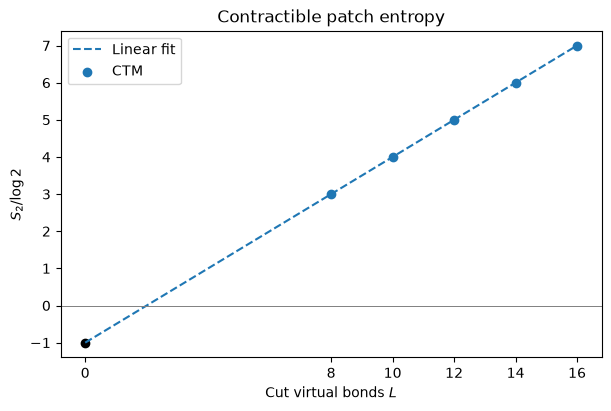

gamma = 0.693147181 = log(2)


In [13]:
# Provided: the width scan, entropy fit, and plot.
def plot_renyi_scaling(boundaries, entropies):
    """Fit S2 = a L - gamma and plot the extrapolation to zero."""
    slope, intercept = np.polyfit(boundaries, entropies, 1)
    x = np.linspace(0, max(boundaries), 100)
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    ax.plot(x, (slope * x + intercept) / np.log(2), "--", label="Linear fit")
    ax.scatter(boundaries, np.asarray(entropies) / np.log(2), label="CTM")
    ax.scatter([0], [intercept / np.log(2)], color="black")
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set(xlabel=r"Cut virtual bonds $L$", ylabel=r"$S_2/\log2$",
           title="Contractible patch entropy", xticks=[0, *boundaries])
    ax.legend()
    plt.show()
    return -intercept


widths = np.arange(2, 7)  # 2 through 6, spacing 1.
patch_boundaries = 2 * (widths + 2)
purities = [ctm_strip_purity(psi_infinite, env_ctm, int(w)) for w in widths]
patch_s2 = -np.log(purities)
print("Width   Cut virtual bonds   S2/log(2)")
for w, boundary, s2 in zip(widths, patch_boundaries, patch_s2):
    print(f"{w:5d}   {boundary:17d}   {s2 / np.log(2):.6f}")

gamma_disk = plot_renyi_scaling(patch_boundaries, patch_s2)
np.testing.assert_allclose(gamma_disk, np.log(2), atol=1e-12)
print(f"gamma = {gamma_disk:.9f} = log(2)")


## Appendix A. Spin correlation functions

- Measure spins separated horizontally by $r$ PEPS-lattice spacings:

  $$
  C_{\alpha\alpha}(r)=
  \langle\sigma^\alpha_{(0,0)}\sigma^\alpha_{(0,r)}\rangle
  -\langle\sigma^\alpha_{(0,0)}\rangle\langle\sigma^\alpha_{(0,r)}\rangle,
  \qquad \alpha=X,Z.
  $$

- `measure_line` contracts the strip between the two operators.
  At this fixed point, $C(0)=1$ and correlations between distinct spins vanish.

- Vanishing local spin correlations do not make this a product state.
  The topological entropy in section 5 detects entanglement beyond these correlators.


 r      C_XX(r)       C_ZZ(r)
 0     1.000e+00     1.000e+00
 1     0.000e+00     0.000e+00
 2     0.000e+00     0.000e+00
 3     0.000e+00     0.000e+00
 4     0.000e+00     0.000e+00
 5     0.000e+00     0.000e+00
 6     0.000e+00     0.000e+00


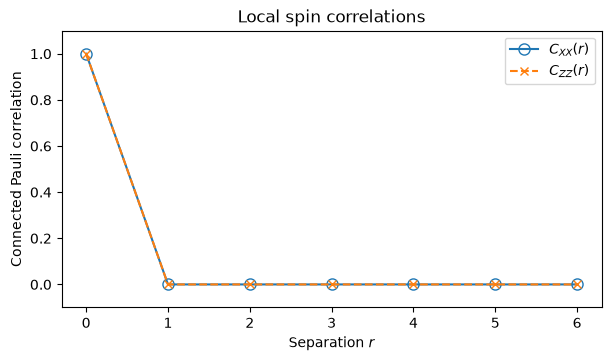

In [14]:
distances = np.arange(7)
correlations = {}
for label, operator in [("X", X), ("Z", Z)]:
    mean = magnetizations[(0, 0), label]
    values = [1 - mean**2]  # Pauli squared is the identity at r = 0.
    values += [
        env_ctm.measure_line(operator, operator, sites=((0, 0), (0, int(r))))
        - mean * magnetizations[(0, int(r) % 2), label]
        for r in distances[1:]
    ]
    correlations[label] = np.array(values)
    np.testing.assert_allclose(values, [1, 0, 0, 0, 0, 0, 0], atol=1e-10)

print(" r      C_XX(r)       C_ZZ(r)")
for r, xx, zz in zip(distances, correlations["X"], correlations["Z"]):
    print(f"{r:2d}    {xx: .3e}    {zz: .3e}")

fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
ax.plot(distances, correlations["X"], "o-", fillstyle="none", markersize=8,
        label=r"$C_{XX}(r)$")
ax.plot(distances, correlations["Z"], "x--", label=r"$C_{ZZ}(r)$")
ax.set(xlabel=r"Separation $r$", ylabel="Connected Pauli correlation",
       title="Local spin correlations", xticks=distances, ylim=(-0.1, 1.1))
ax.legend()
plt.show()


## Appendix B. Finite-torus calculations

- These optional checks use the same `unit_cell`, with one qubit per site.
  Both periodic dimensions must be even to preserve the checkerboard pattern.

- For these small full wavefunctions, contract dense copies of the YASTN site
  tensors with NumPy.


In [15]:
def torus_state(unit_cell, width, height=2, twist_x=False, twist_y=False):
    """Periodic PEPS with optional virtual Z gates across the two seams."""
    assert width % 2 == height % 2 == 0  # Periodic checkerboard.
    # Virtual bonds point right and down, including across periodic seams.
    sites = list(product(range(height), range(width)))
    up = {site: 2*i for i, site in enumerate(sites)}
    right = {site: 2*i + 1 for i, site in enumerate(sites)}
    labels = [[up[r, c], right[r, (c-1) % width],
               up[(r+1) % height, c], right[r, c], 2*len(sites) + i]
              for i, (r, c) in enumerate(sites)]
    tensors = [unit_cell[r % 2, c % 2] for r, c in sites]
    Zv = yastn.Tensor(config=tensors[0].config, s=(1, -1), n=0)
    for q in (0, 1):
        Zv.set_block(ts=(q, q), Ds=(1, 1), val=np.array([[(-1.)**q]]))
    # Absorb seam gates into their site tensors.
    for i, (r, c) in enumerate(sites):
        if twist_x and c == width - 1:
            tensors[i] = yastn.einsum("uldap,ar->uldrp", tensors[i], Zv)
        if twist_y and r == height - 1:
            tensors[i] = yastn.einsum("ularp,ad->uldrp", tensors[i], Zv)
    # Small appendix states: contract dense copies of the YASTN site tensors.
    network = []
    for tensor, indices in zip(tensors, labels):
        network.extend((tensor.to_numpy(), indices))
    output = list(range(2 * len(sites), 3 * len(sites)))
    return np.einsum(*network, output, optimize=True).reshape(-1)


def apply_x_row(state, width):
    """Apply X to every spin in the first row."""
    n = int(np.log2(state.size))
    return np.flip(state.reshape((2,) * n), axis=tuple(range(width))).reshape(-1)


def apply_z_row(state, width):
    """Apply Z to every spin in the first row."""
    signs = np.array([(-1.)**sum(bits) for bits in product((0, 1), repeat=width)])
    return (signs[:, None] * state.reshape(2**width, -1)).reshape(-1)


### B.1. Entanglement spectrum on a small torus

- Contract a torus of two rows and four columns. Split it into its two rows,
  each containing four physical qubits:

  ```text
      R:  A --> B --> A --> B
          |     |     |     |
          v     v     v     v
      S:  B --> A --> B --> A
  ```

- Reshape the normalized wavefunction into a matrix and take its Schmidt decomposition:

  $$
  \Psi_{rs}=U\,\mathrm{diag}(s_i)\,V^\dagger,\qquad
  \lambda_i=s_i^2,\qquad \xi_i=-\log\lambda_i.
  $$

- The $\lambda_i$ are the eigenvalues of $\rho_R$; the $\xi_i$ form the entanglement
  spectrum. For this unprojected PEPS state and cut, eight eigenvalues equal $1/8$ and eight vanish:

  $$
  S_R=-\sum_i\lambda_i\log\lambda_i=3\log2.
  $$

- The nonzero spectrum is flat. Omit zero eigenvalues, whose entanglement energies
  are infinite. Sector projection for this cut is introduced next.


Nonzero eigenvalues of rho_R: [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
S_R / log(2) = 3.000000


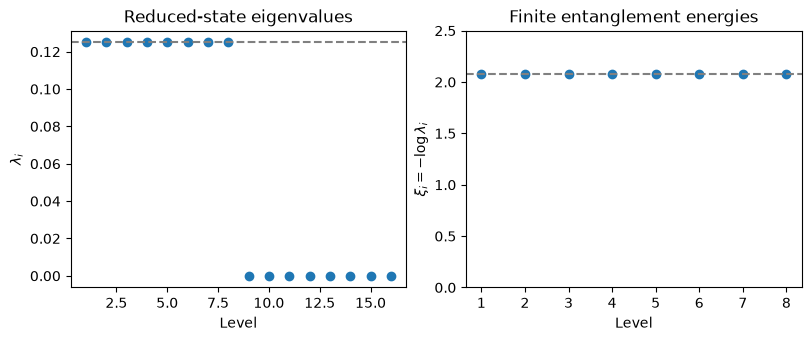

In [16]:
# Two rows, four columns, and one physical spin per site.
psi = torus_state(unit_cell, 4)
psi /= np.linalg.norm(psi)

# Row-major site order: first row, then second row.
wavefunction_matrix = psi.reshape(2**4, 2**4)
schmidt_values = np.linalg.svd(wavefunction_matrix, compute_uv=False)
rho_eigenvalues = schmidt_values**2
nonzero = rho_eigenvalues[rho_eigenvalues > 1e-12]
entanglement_energies = -np.log(nonzero)
entropy = -np.sum(nonzero * np.log(nonzero))

np.testing.assert_allclose(nonzero, np.full(8, 1 / 8), atol=1e-14)
np.testing.assert_allclose(rho_eigenvalues[8:], 0, atol=1e-14)
np.testing.assert_allclose(entropy, 3 * np.log(2), atol=1e-14)
print("Nonzero eigenvalues of rho_R:", nonzero)
print(f"S_R / log(2) = {entropy / np.log(2):.6f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.3), constrained_layout=True)
axes[0].scatter(np.arange(1, 17), rho_eigenvalues)
axes[0].set(xlabel="Level", ylabel=r"$\lambda_i$", title="Reduced-state eigenvalues")
axes[0].axhline(1 / 8, color="gray", linestyle="--")
axes[1].scatter(np.arange(1, len(nonzero) + 1), entanglement_energies)
axes[1].axhline(np.log(8), color="gray", linestyle="--")
axes[1].set(xlabel="Level", ylabel=r"$\xi_i = -\log\lambda_i$",
            title="Finite entanglement energies", ylim=(0, 2.5))
plt.show()


### B.2. Torus Rényi entropy and topological sectors

- Partition a torus of two rows and $w$ columns into its two rows.
  There are **two boundaries**, each crossing $w$ virtual bonds.
  For a minimally entangled toric-code state in this geometry,

  $$
  S_2=\frac{L}{2}\log2-2\gamma,\qquad L=2w,\qquad\gamma=\log2.
  $$

- Use even widths $w=2,4,6,8$ to preserve the checkerboard pattern.
  Fit $S_2=aL+b$ and extract $\gamma=-b/2$.

- For a row $\ell$, choose the commuting Wilson operators

  $$
  W_Z=\prod_{j\in\ell}Z_j,\qquad W_X=\prod_{j\in\ell}X_j.
  $$

- A virtual **$Z$ seam** changes $W_X$ for this tensor representation.
  Then apply $(I+w_ZW_Z)/2$ to select $W_Z=w_Z$.
  These two labels specify the four minimally entangled sectors for the row cut.

- All four sectors have the same entropy. The unprojected PEPS state has an
  additional $\log2$ from its superposition of two $W_Z$ sectors.


In [17]:
def row_renyi2(state, width):
    """Purity entropy between the two rows of a width-by-two torus."""
    matrix = state.reshape(2**width, 2**width) / np.linalg.norm(state)
    rho = matrix @ matrix.conj().T
    return -np.log(np.sum(abs(rho)**2))


torus_widths = np.arange(2, 9, 2)
boundary_lengths = 2 * torus_widths
sector_entropies = {(wx, wz): [] for wx in (1, -1) for wz in (1, -1)}
for width in torus_widths:
    for wx in (1, -1):
        base = torus_state(unit_cell, int(width), twist_x=(wx == -1))
        np.testing.assert_allclose(row_renyi2(base, width), (width - 1) * np.log(2), atol=1e-12)
        for wz in (1, -1):
            state = base + wz * apply_z_row(base, width)
            sector_entropies[wx, wz].append(row_renyi2(state, width))
    print(f"w = {width}: sector S2 / log(2) =",
          [round(values[-1] / np.log(2), 6) for values in sector_entropies.values()])

# Verify both Wilson labels and orthogonality on the smallest torus.
bits = np.array(list(product((0, 1), repeat=4)))
wz_diagonal = (-1.)**bits[:, :2].sum(axis=1)
sector_states = []
for wx, wz in sector_entropies:
    base = torus_state(unit_cell, 2, twist_x=(wx == -1))
    state = base + wz * apply_z_row(base, 2)
    state /= np.linalg.norm(state)
    np.testing.assert_allclose(np.vdot(state, apply_x_row(state, 2)), wx, atol=1e-12)
    np.testing.assert_allclose(np.dot(abs(state)**2, wz_diagonal), wz, atol=1e-12)
    sector_states.append(state)
np.testing.assert_allclose(np.array(sector_states) @ np.array(sector_states).conj().T,
                           np.eye(4), atol=1e-12)


w = 2: sector S2 / log(2) = [np.float64(-0.0), np.float64(-0.0), np.float64(-0.0), np.float64(-0.0)]
w = 4: sector S2 / log(2) = [np.float64(2.0), np.float64(2.0), np.float64(2.0), np.float64(2.0)]
w = 6: sector S2 / log(2) = [np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0)]
w = 8: sector S2 / log(2) = [np.float64(6.0), np.float64(6.0), np.float64(6.0), np.float64(6.0)]


 WX  WZ   slope/log(2)   intercept/log(2)   gamma/log(2)
 +1  +1      0.500000          -2.000000        1.000000
 +1  -1      0.500000          -2.000000        1.000000
 -1  +1      0.500000          -2.000000        1.000000
 -1  -1      0.500000          -2.000000        1.000000


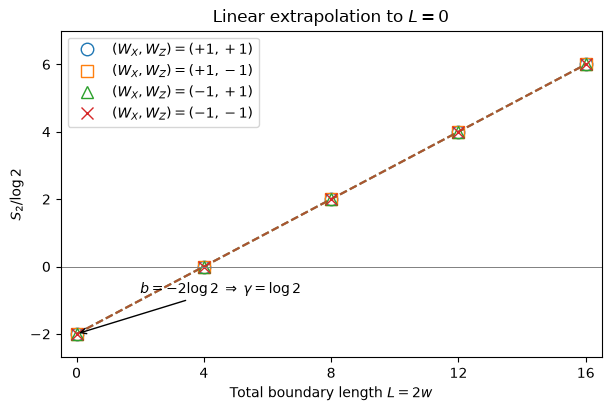

In [18]:
fit_lengths = np.linspace(0, boundary_lengths.max(), 100)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
markers = ["o", "s", "^", "x"]
print(" WX  WZ   slope/log(2)   intercept/log(2)   gamma/log(2)")
for ((wx, wz), entropies), marker in zip(sector_entropies.items(), markers):
    slope, intercept = np.polyfit(boundary_lengths, entropies, 1)
    gamma = -intercept / 2  # Two boundary components.
    np.testing.assert_allclose(slope, 0.5 * np.log(2), atol=1e-12)
    np.testing.assert_allclose(gamma, np.log(2), atol=1e-12)
    print(f"{wx:+3d} {wz:+3d}      {slope / np.log(2):.6f}          "
          f"{intercept / np.log(2):.6f}        {gamma / np.log(2):.6f}")
    line, = ax.plot(fit_lengths, (slope * fit_lengths + intercept) / np.log(2),
                    linestyle="--", alpha=0.6)
    ax.plot(boundary_lengths, np.array(entropies) / np.log(2),
            linestyle="none", marker=marker, markersize=9, fillstyle="none",
            color=line.get_color(), label=fr"$(W_X,W_Z)=({wx:+d},{wz:+d})$")
    ax.plot(0, intercept / np.log(2), marker=marker, markersize=9,
            fillstyle="none", color=line.get_color())
ax.axhline(0, color="gray", linewidth=0.7)
ax.annotate(r"$b=-2\log2\;\Rightarrow\;\gamma=\log2$", xy=(0, -2),
            xytext=(2.0, -0.8), arrowprops={"arrowstyle": "->"})
ax.set(xlabel=r"Total boundary length $L=2w$", ylabel=r"$S_2 / \log 2$",
       title=r"Linear extrapolation to $L=0$", xticks=[0, *boundary_lengths],
       xlim=(-0.5, boundary_lengths.max() + 0.5), ylim=(-2.7, 7))
ax.legend()
plt.show()


### B.3. Check sector independence

- Compare the $2\times2$ site CTM RDM with the same region in all four
  $4\times4$ torus sectors, and in an unprojected PEPS state.
  This region supports no noncontractible Wilson loop.


In [19]:
def reduced_density_matrix(state, region_qubits, n_qubits):
    """Trace out all physical qubits outside a region."""
    complement = [q for q in range(n_qubits) if q not in region_qubits]
    matrix = state.reshape((2,) * n_qubits).transpose(region_qubits + complement)
    matrix = matrix.reshape(2**len(region_qubits), -1)
    rho = matrix @ matrix.conj().T
    return rho / np.trace(rho)


rho_patch = ctm_strip_rdm(psi_infinite, env_ctm, 2).to_numpy()
# CTM spin order: top/bottom in column 0, then top/bottom in column 1.
region_qubits = [0, 4, 1, 5]  # Row-major indexing on a 4x4 torus.
print(" WX  WZ   max RDM difference from CTM   S2/log(2)")
for wx in (1, -1):
    base = torus_state(unit_cell, 4, 4, twist_x=(wx == -1))
    for wz in (1, -1):
        state = base + wz * apply_z_row(base, 4)
        rho = reduced_density_matrix(state, region_qubits, 16)
        difference = np.max(abs(rho - rho_patch))
        np.testing.assert_allclose(rho, rho_patch, atol=1e-12)
        s2 = -np.log(np.einsum("ij,ji->", rho, rho).real)
        print(f"{wx:+3d} {wz:+3d}             {difference:.2e}              {s2 / np.log(2):.6f}")
rho_unprojected = reduced_density_matrix(base, region_qubits, 16)
np.testing.assert_allclose(rho_unprojected, rho_patch, atol=1e-12)
print("The unprojected PEPS state gives the same local RDM.")


 WX  WZ   max RDM difference from CTM   S2/log(2)
 +1  +1             0.00e+00              3.000000
 +1  -1             0.00e+00              3.000000
 -1  +1             0.00e+00              3.000000
 -1  -1             0.00e+00              3.000000
The unprojected PEPS state gives the same local RDM.


## References

- [YASTN: symmetric tensor construction](https://yastn.github.io/yastn/tensor/init.html).
- [Schuch, Cirac, and Pérez-García (2010)](https://arxiv.org/abs/1001.3807):
  toric-code PEPS, virtual symmetries, and renormalization.
- [Zhang et al. (2012)](https://arxiv.org/abs/1111.2342):
  ground-state dependence of entropy for noncontractible cuts.
- [Kitaev (2003), Section 1](https://arxiv.org/abs/quant-ph/9707021):
  toric-code Hamiltonian, loop states, and fourfold torus degeneracy.
- [Schuch et al. (2012), Section II.E](https://arxiv.org/abs/1203.4816):
  toric code on a checkerboard square lattice.
- [Flammia et al. (2009)](https://arxiv.org/abs/0909.3305):
  topological corrections to Rényi entropies.
